# QUEST: why post-processing belongs to the model

## tl;dr

Selective rounding improves the predeclared nested Ridge fold mean **0.326727 → 0.345104** (all five folds), with pooled OOF **0.326114 → 0.331345**. A strictly increasing rescaling changes neither result. The saved DeBERTa diagnostics are less conclusive: fold mean improves but pooled performance declines, and checkpoint-selection bias remains. Keep the method; do not promote a transformer policy from these diagnostics.

This walkthrough explains the original solution's metric-aware idea. It uses published aggregate evidence and synthetic values, with no private text, IDs, thresholds, GPU or Kaggle credentials.

**Follow-up:** single-policy transfers improve in 8/10 directions (mean +0.004489), with one seed negative in both directions. The frozen candidate matches all 476×30 outputs after reload; one fixed candidate subsequently improves both public and private leaderboard scores.

**One-shot external result:** same checkpoint and raw outputs, public **0.35189 → 0.36136**, private **0.32983 → 0.34370**. Public Top **72.84%** against the dated reference; still below the historical account score. Exact hosted parity and the paired submission are retained in aggregate receipts.

## Context & Methods

Spearman correlates average ranks, including tied ranks. Rounding can create ties; a strictly increasing map cannot. The original notebook fitted cut points and selected target columns on the same validation labels, displaying 0.386 → 0.415. That is archival fit evidence rather than independent validation.

### Key Assumptions

The primary new assessment is five outer question-group folds, with three inner folds to fit each postprocessor from outer-training OOF predictions. Vocabulary, IDF, model coefficients, label support, cuts and target selection do not use outer-assessment labels. All 30 targets remain in the denominator, undefined correlations contribute zero. Fold SD is descriptive, and this single split plan does not quantify seed sensitivity.

The DeBERTa checkpoint was selected on its complete holdout, so cross-fitting its postprocessor is a retrospective diagnostic. [Protocol](../docs/postprocessing-protocol.md) · [Full interpretation](../docs/postprocessing-study.md).

## Data

Load the committed aggregate receipt. Private train/holdout predictions and fitted policies remain outside Git. The clean study source, script hash, input hash, split hash and package versions are retained in this receipt.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from quest.postprocessing import OptimalRounder

root = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
receipt = json.loads((root / "docs/postprocessing-study.json").read_text())
assert receipt["status"] == "completed" and receipt["source"]["git_dirty"] is False
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
print("Study source:", receipt["source"]["git_commit"])
print("Environment:", receipt["environment"])

Study source: fa949d2729d9707164bbba2f9473f07f6a8fa3e0
Environment: {'numpy': '2.5.4', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'quest-labeling': '0.2.0.dev3'}


## Results

### 1. Change ties, not just score scale

Four synthetic examples show the mechanism. The 1.0 score below is deliberately fitted/evaluated on the same four examples to illustrate ties; it is not validation evidence.

In [2]:
actual = pd.DataFrame({"target": [0., 0., 1., 1.]})
raw = pd.DataFrame({"target": [0.1, 0.2, 0.3, 0.4]})
rounded = OptimalRounder().fit(actual, raw).transform(raw)
demo = pd.DataFrame({"truth": actual.target, "raw": raw.target,
                     "raw_squared": raw.target ** 2, "rounded": rounded.target})
display(demo)
display(pd.Series({name: spearmanr(demo.truth, demo[name]).statistic
                   for name in ["raw", "raw_squared", "rounded"]}, name="Spearman"))

,truth,raw,raw_squared,rounded
0,0.0,0.1,0.01,0.0
1,0.0,0.2,0.04,0.0
2,1.0,0.3,0.09,1.0
3,1.0,0.4,0.16,1.0


raw            0.894427
raw_squared    0.894427
rounded        1.000000
Name: Spearman, dtype: float64

### 2. Assess on outer folds the rounder has not seen

Fold mean is the primary metric. The pooled score is also necessary: combining different fold-specific tie policies changes cross-fold rank comparisons. The monotone-square control matches raw exactly.

,Fold mean,Fold SD (descriptive),Pooled OOF
raw,0.326727,0.003205,0.326114
monotone_square,0.326727,0.003205,0.326114
rounded_all,0.337643,0.007947,0.318571
rounded_selective,0.345104,0.007390,0.331345


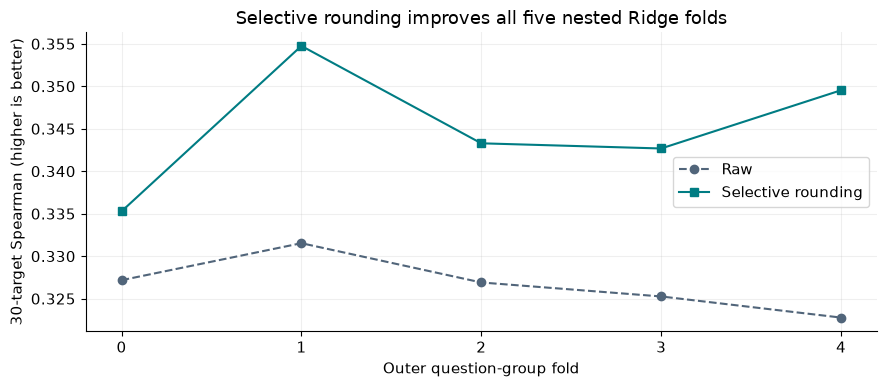

In [3]:
conditions = receipt["nested_ridge"]["conditions"]
table = pd.DataFrame({name: {"Fold mean": value["primary_fold_mean_spearman"],
                            "Fold SD (descriptive)": value["fold_sd_descriptive"],
                            "Pooled OOF": value["pooled"]["mean_spearman_30_zero_fallback"]}
                      for name, value in conditions.items()}).T
display(table.round(6))
assert conditions["raw"] == conditions["monotone_square"]
folds = receipt["nested_ridge"]["folds"]
raw_fold = np.array([r["scores"]["raw"]["mean_spearman_30_zero_fallback"] for r in folds])
rounded_fold = np.array([r["scores"]["rounded_selective"]["mean_spearman_30_zero_fallback"] for r in folds])
assert (rounded_fold > raw_fold).all()
fig, ax = plt.subplots()
ax.plot(range(5), raw_fold, "o--", color="#51657a", label="Raw")
ax.plot(range(5), rounded_fold, "s-", color="#007c83", label="Selective rounding")
ax.set(xticks=range(5), xlabel="Outer question-group fold", ylabel="30-target Spearman (higher is better)",
       title="Selective rounding improves all five nested Ridge folds")
ax.legend(); fig.tight_layout(); plt.show()

The fold improvement is consistent in direction within this plan; dispersion increases after rounding. This is not a claim about five-fold transformer performance, independent seeds or leaderboard improvement.

### 3. Expose the saved-transformer diagnostic's limitations

The same-holdout fitting result is optimistic. Cross-fitting only the rounder leaves the earlier checkpoint-selection bias intact. Compare fold mean with pooled rank behavior before deciding whether to promote anything.

,Same-label fit/evaluate (optimistic),Calibration crossfit fold mean (diagnostic),Calibration crossfit pooled (diagnostic)
Raw,0.377863,0.375006,0.377863
Selective rounding,0.411136,0.382324,0.365200


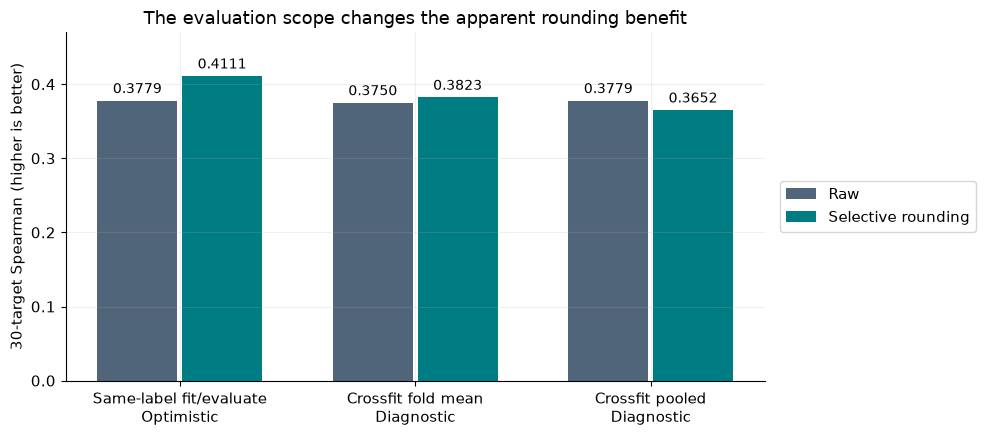

In [4]:
transformer = receipt["retained_transformer"]
diag = transformer["calibration_crossfit_diagnostic"]["conditions"]
same = transformer["same_label_fit_evaluation_optimistic"]
comparison = pd.DataFrame({
    "Same-label fit/evaluate (optimistic)": [same[n]["mean_spearman_30_zero_fallback"] for n in ["raw", "rounded_selective"]],
    "Calibration crossfit fold mean (diagnostic)": [diag[n]["primary_fold_mean_spearman"] for n in ["raw", "rounded_selective"]],
    "Calibration crossfit pooled (diagnostic)": [diag[n]["pooled"]["mean_spearman_30_zero_fallback"] for n in ["raw", "rounded_selective"]],
}, index=["Raw", "Selective rounding"])
display(comparison.round(6))
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(comparison.columns))
for offset, label, color in [(-0.18, "Raw", "#51657a"), (0.18, "Selective rounding", "#007c83")]:
    values = comparison.loc[label].to_numpy()
    bars = ax.bar(x + offset, values, width=.34, label=label, color=color)
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=10)
ax.set(xticks=x, xticklabels=["Same-label fit/evaluate\nOptimistic", "Crossfit fold mean\nDiagnostic", "Crossfit pooled\nDiagnostic"],
       ylabel="30-target Spearman (higher is better)", ylim=(0, .47),
       title="The evaluation scope changes the apparent rounding benefit")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); fig.tight_layout(); plt.show()

### 4. Follow-up: does a single policy transfer to another population?

Five predeclared question-group split seeds each partition the same saved holdout into two halves. Calibrate on one, assess on the other, then reverse. This tests a policy on a single assessment population without mixing different policies' scales in the primary metric. The encoder checkpoint still saw the full holdout during checkpoint selection, so these are robustness diagnostics, not independent model acceptance results.

,Seed,Assessment half,Raw Spearman,Rounded Spearman,Delta
0,42,0,0.386761,0.387532,0.000771
1,42,1,0.366926,0.374885,0.007959
2,1017,0,0.371534,0.377948,0.006414
3,1017,1,0.381533,0.387875,0.006342
4,2027,0,0.388571,0.387336,-0.001235
5,2027,1,0.364301,0.360956,-0.003345
6,3407,0,0.375462,0.380182,0.004720
7,3407,1,0.378477,0.378579,0.000102
8,7919,0,0.373747,0.393053,0.019306
9,7919,1,0.379110,0.382970,0.003859


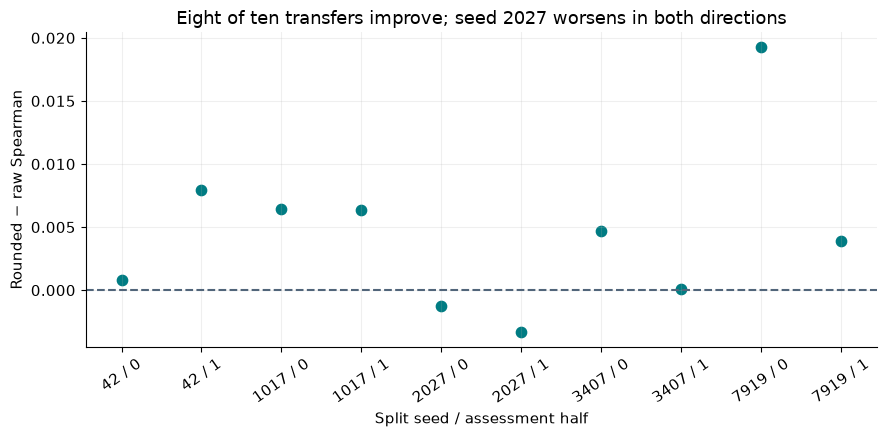

Mean paired delta: +0.004489; overlapping splits, no independent-sample CI


In [5]:
transfer = json.loads((root / "docs/deberta-rounding-transfer.json").read_text())
rows = pd.DataFrame([{"Seed": r["seed"], "Assessment half": r["assessment_half"],
                      "Raw Spearman": r["raw"]["mean_spearman_30_zero_fallback"],
                      "Rounded Spearman": r["selective"]["mean_spearman_30_zero_fallback"],
                      "Delta": r["delta"]} for r in transfer["transfers"]])
display(rows.round(6))
assert (rows.Delta > 0).sum() == transfer["positive_transfers"] == 8
assert abs(rows.Delta.mean() - transfer["mean_paired_delta"]) < 1e-12
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(rows))
ax.scatter(positions, rows.Delta, marker="o", color="#007c83", s=55)
ax.axhline(0, color="#51657a", linestyle="--")
ax.set(xticks=positions, xticklabels=[f"{int(r.Seed)} / {int(r['Assessment half'])}" for _, r in rows.iterrows()],
       xlabel="Split seed / assessment half", ylabel="Rounded − raw Spearman",
       title="Eight of ten transfers improve; seed 2027 worsens in both directions")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout(); plt.show()
print(f"Mean paired delta: {rows.Delta.mean():+.6f}; overlapping splits, no independent-sample CI")

The mean paired delta is **+0.004489**. All split results remain visible; one negative seed limits the stability claim. The candidate is the original canary-3 full-holdout policy, fixed before this follow-up rather than chosen using these results.

A separate label-free diagnostic normalizes each earlier assessment partition to its own average-rank percentiles. Within-partition Spearman stays unchanged, yet pooled rounded performance drops further. This attempted normalization does not repair the earlier result and is not part of the candidate.

In [6]:
scale = transfer["crossfold_scale_diagnostic"]
scale_table = pd.DataFrame({label: {method: value["mean_spearman_30_zero_fallback"]
                                  for method, value in scale[key].items()}
                           for key, label in [("original_pooled", "Original pooled"),
                                              ("within_assessment_rank_percentile_pooled", "Partition-rank-normalized pooled")]})
display(scale_table.round(6))
local = transfer["publication"]["notebook_local_validation"]
assert local["maximum_prediction_difference"] == 0 and local["rows"] == 476
print("Candidate application parity: 476 × 30 outputs, max difference 0.")
hosted = json.loads((root / "docs/deberta-rounding-hosted.json").read_text())
scoring = json.loads((root / "docs/deberta-rounding-scoring.json").read_text())
assert hosted["raw_max_probability_delta_vs_previous_scored_inference"] == 0
assert hosted["rounded_max_probability_delta_vs_local_candidate"] == 0
assert scoring["submission"]["status"] == "SubmissionStatus.COMPLETE"
print("Hosted fresh inference parity: raw and rounded maximum difference 0.")
external = pd.DataFrame({"Public Spearman": [float(scoring["base_raw_public_score"]), float(scoring["submission"]["publicScore"])],
                         "Private Spearman": [float(scoring["base_raw_private_score"]), float(scoring["submission"]["privateScore"])]},
                        index=["Raw", "Fixed rounding"])
display(external)
display(external.loc["Fixed rounding"] - external.loc["Raw"])

,Original pooled,Partition-rank-normalized pooled
raw,0.377863,0.375943
rounded_selective,0.365200,0.331452


Candidate application parity: 476 × 30 outputs, max difference 0.
Hosted fresh inference parity: raw and rounded maximum difference 0.


,Public Spearman,Private Spearman
Raw,0.35189,0.32983
Fixed rounding,0.36136,0.34370


Public Spearman     0.00947
Private Spearman    0.01387
dtype: float64

The local notebook application check uses the real retained raw predictions, not synthetic predictions. It does not claim the entire GPU inference notebook executed locally. The private staged notebook would run fresh inference before applying the same frozen policy. Private Kaggle version 1 subsequently completed offline inference with exact raw and rounded parity. One scoring request improves public/private Spearman to **0.36136 / 0.34370**; this does not automatically promote the policy to serving. [Complete protocol, evidence and status](../docs/deberta-rounding-transfer.md).

## Takeaways

- **Research:** metric-aware rounding is a real modeling choice: tying predictions can improve Spearman even though monotone score rescaling cannot. The strict nested Ridge result supports the approach on this baseline.
- **Engineering:** the model's contract includes its fitted postprocessor, target order, calibration identity and policy checksum. Persist that state and verify it after reload.
- **Decision:** keep transformer raw serving unchanged. Its fold-mean increase and pooled decline, together with checkpoint-selection bias, do not support automatic promotion. Use training OOF to fit a policy and a separate question-group acceptance population to test the complete prediction path.

The tested application path reloaded a policy and preserved all 476 test IDs/order and the source file hash. It produced a separate, unsubmitted example only. [Application and reproduction recipe](../docs/postprocessing-study.md#reproduce-and-apply).

Historical public/private LB **0.43155 / 0.40232**, Public Top **5.22%** against the dated public snapshot, remains distinct from these retrospective experiments. [Leaderboard evidence](../docs/results.md#leaderboard-percentile-context).